# First Look at Vulnerability Data

Get up and running with vulnflow in minutes. This notebook pulls the NVD
"Recent" feed (CVEs published in the last ~8 days), enriches it, and
explores basic severity and exploitation-probability distributions.

CacheBuilder is a helper class that wraps the VulnPipeline and provides a simple 
interface for building a cache of vulnerability data. It can be used to build a cache
of recent vulnerabilities, or to build a cache of all vulnerabilities.

In [1]:
from vulnflow.helpers import CacheBuilder

ds = CacheBuilder(recent_only=True).build()

Processing NVD feeds:   0%|          | 0/1 [00:00]

Enriching & transforming:   0%|          | 0/8 [00:00]

In [2]:
df = ds.to_pandas()
print(f"Records Loaded: {len(ds):,}")
print(f"Columns : {len(df.columns)}")
print(f"Date range : {df['nvd_published_at'].min()} .. {df['nvd_published_at'].max()}")
print(f"Avg CVSS : {df['cvss_base_score'].mean():.1f}")
df.head(3)

Records Loaded: 3,924
Columns : 47
Date range : 2026-10-29 04:18:22.763000+00:00 .. 2026-11-06 12:17:24.820000+00:00
Avg CVSS : 6.9


,id,cve_id,description,nvd_published_at,nvd_modified_at,nvd_status,cvss_version,cvss_base_score,cvss_base_severity,cvss_source,...,cwe_category_name,cwe_abstraction_level,cpe_vendor,cpe_product,cpe_version,cpe_fix_version,capecs,stride_threats,tags,metadata
0,a820b1cd-7e6f-4ab7-a8b4-d4ba1dc78ddd,CVE-2026-109516,The Bot for Telegram on WooCommerce plugin for...,2026-10-29 04:18:22.763+00:00,2026-10-29 14:56:26.107+00:00,deferred,3.1,9.8,CRITICAL,wordfence,...,Improper Access Control,Class,NaN,NaN,NaN,NaN,[],[],{},{}
1,935e3e48-5fa8-439a-9c82-f3168c8c4555,CVE-2026-118426,In affected versions of Octopus Server with th...,2026-10-29 04:18:35.260+00:00,2026-11-05 17:17:52.860+00:00,awaiting,4.0,5.3,MEDIUM,octopus,...,Improper Authorization,Class,NaN,NaN,NaN,NaN,[],[],{},{}
2,2af45f1b-f460-4872-9dbc-9f5c90809a4c,CVE-2026-40063,A information disclosure vulnerability exists ...,2026-10-29 04:18:36.300+00:00,2026-10-29 16:21:34.310+00:00,deferred,3.1,5.3,MEDIUM,cisco,...,Exposure of Resource to Wrong Sphere,Class,NaN,NaN,NaN,NaN,[],[],{},{}


## Severity Distribution

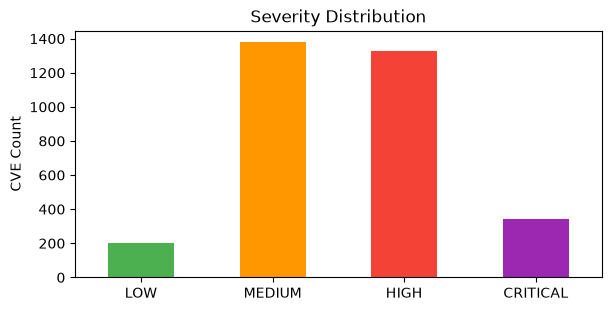

In [3]:
import matplotlib.pyplot as plt

severity_order = ["LOW", "MEDIUM", "HIGH", "CRITICAL"]
colors = {"LOW": "#4caf50", "MEDIUM": "#ff9800", "HIGH": "#f44336", "CRITICAL": "#9c27b0"}

counts = (
    df["cvss_base_severity"]
    .value_counts()
    .reindex(severity_order)
    .dropna()
)

fig, ax = plt.subplots(figsize=(6, 3), layout="constrained")
counts.plot.bar(ax=ax, color=[colors.get(s, "#999") for s in counts.index])
ax.set_title("Severity Distribution")
ax.set_ylabel("CVE Count")
ax.set_xlabel("")
plt.xticks(rotation=0)
plt.show()

## Most Critical

Top 10 CVEs by base score (>= 9.0).

In [4]:
critical = (
    df.loc[df["cvss_base_score"] >= 9.0]
    .sort_values("cvss_base_score", ascending=False)
    .head(10)
)
critical[["cve_id", "cvss_base_score", "cvss_base_severity", "epss_probability", "cwe_name", "description"]]

,cve_id,cvss_base_score,cvss_base_severity,epss_probability,cwe_name,description
1368,CVE-2026-120338,10.0,CRITICAL,0.00771,Improper Control of Generation of Code ('Code ...,Prefab UI's Generative UI sandbox runs caller-...
3139,CVE-2026-121489,10.0,CRITICAL,0.00496,Improper Limitation of a Pathname to a Restric...,Improper Limitation of a Pathname to a Restric...
1402,CVE-2026-120277,10.0,CRITICAL,0.02451,Improper Neutralization of Special Elements us...,A security vulnerability has been detected in ...
1406,CVE-2026-120281,10.0,CRITICAL,0.00584,Improper Restriction of Operations within the ...,A vulnerability was found in WAVLINK WN536AX6-...
3149,CVE-2026-96677,10.0,CRITICAL,0.00444,Improper Neutralization of Input During Web Pa...,Improper Neutralization of Input During Web Pa...
339,CVE-2026-61991,10.0,CRITICAL,0.00748,Improper Control of Generation of Code ('Code ...,Unauthenticated Remote Code Execution (RCE) in...
3148,CVE-2026-73117,10.0,CRITICAL,0.00444,Improper Neutralization of CRLF Sequences in H...,Improper Neutralization of CRLF Sequences in H...
3147,CVE-2026-73116,10.0,CRITICAL,0.00406,Insufficiently Protected Credentials,Insufficiently Protected Credentials vulnerabi...
3146,CVE-2026-73101,10.0,CRITICAL,0.00428,Generation of Error Message Containing Sensiti...,Generation of Error Message Containing Sensiti...
3145,CVE-2026-73100,10.0,CRITICAL,0.00428,Insertion of Sensitive Information into Log File,Insertion of Sensitive Information into Log Fi...


## EPSS vs CVSS

Scatter plot with quadrant lines at CVSS = 7 and EPSS = 0.1.
Points in the upper-right quadrant are both high-severity and
likely exploited — prioritize these.

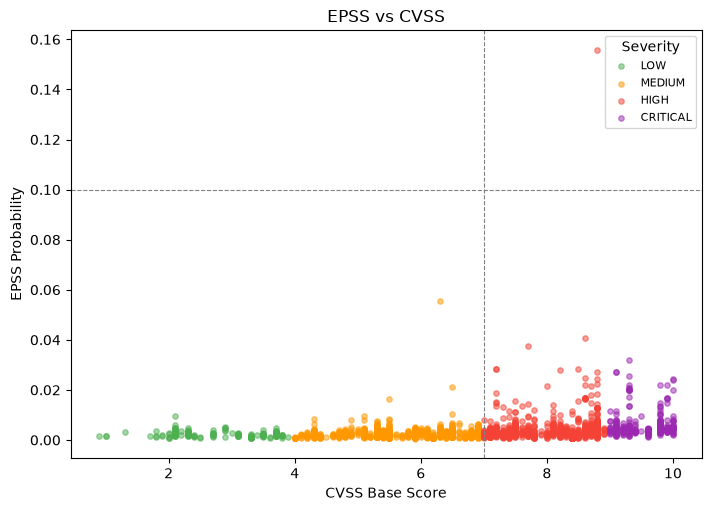

In [5]:
plot_df = df.dropna(subset=["cvss_base_score", "epss_probability"])

fig, ax = plt.subplots(figsize=(7, 5), layout="constrained")
for sev in severity_order:
    subset = plot_df[plot_df["cvss_base_severity"] == sev]
    ax.scatter(
        subset["cvss_base_score"],
        subset["epss_probability"],
        label=sev,
        color=colors.get(sev, "#999"),
        alpha=0.5,
        s=15,
    )

ax.axvline(7, color="grey", linestyle="--", linewidth=0.8)
ax.axhline(0.1, color="grey", linestyle="--", linewidth=0.8)
ax.set_xlabel("CVSS Base Score")
ax.set_ylabel("EPSS Probability")
ax.set_title("EPSS vs CVSS")
ax.legend(title="Severity", fontsize=8)
plt.show()

## Save for Later

Write the dataset to Parquet for fast reloading.

In [6]:
ds.to_parquet("../data/modified_cache.parquet")
print("Saved to ../data/modified_cache.parquet")

Saved to ../data/modified_cache.parquet
